# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus). Per the **derive-don't-inherit** mandate
we do not inherit that pair. We first score a **broad EMT-TF candidate panel** — the canonical
Snail/Zeb/Twist factors, the mesenchymal **FOXC / PRRX** families (added per the Kürten lesson —
VIM is a marker, not a TF, and is excluded), and the neural-crest / mesenchymal master regulators
(**SOX4/SOX9/TBX3/ID1-3/LEF1/TCF3-4/RUNX2/GSC/MSX1-2**) — then **gate on detectable expression**
(≥3 % of cells) and let the data choose the most end-specific factor at each trajectory end.

**Detection finding (dataset-specific).** In this SmartSeq2 metastatic-prostate malignant set the
**canonical EMT-TFs are essentially undetectable**: SNAI1/ZEB1/ZEB2/TWIST1 are all expressed in <2 %
of cells, and SNAI2/TWIST2/FOXC1/FOXC2/PRRX1/PRRX2 are absent from the filtered matrix entirely.
Overlaying them would paint noise. The detectable EMT signal is instead carried by the
**neural-crest / mesenchymal TF program** (SOX4, TBX3, ID2, SOX9, TCF3, LEF1), which rises coherently
toward the neural-crest terminus. We therefore overlay the two most end-specific *detectable* factors,
consistent with the gate-on-detection rule. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 833 | pseudotime range 0.0 -> 11.12


### Derive the end-specific EMT-TFs (data-driven, detection-gated)
For each candidate TF: fraction of cells expressing, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Factors below a **3 %
expression floor** are too sparse to overlay and are dropped (this removes all canonical
Snail/Zeb/Twist here). Among the survivors, the most negative pseudotime-correlation marks the root
end and the most positive marks the terminus.

In [4]:
panel = ['SNAI1','SNAI2','SNAI3','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2',
         'SOX4','SOX9','TBX3','ID1','ID2','ID3','LEF1','TCF3','TCF4','RUNX2','GSC','MSX1','MSX2','NR2F1']
present = [g for g in panel if g in adata.var_names]
absent  = [g for g in panel if g not in adata.var_names]
print('candidates present:', present)
print('candidates absent from filtered matrix:', absent)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
pd.set_option('display.width', 160)
print(df.to_string(index=False))
canon = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2']
print('\ncanonical Snail/Zeb/Twist detection:',
      {g: float(df.loc[df.TF==g,'frac_expr'].iloc[0]) for g in canon if g in present},
      '-> all below the 3% floor' )
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetectable EMT-TFs above floor: {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root end) <-> {late_tf} (late/terminus end)')

candidates present: ['SNAI1', 'SNAI3', 'ZEB1', 'ZEB2', 'TWIST1', 'SOX4', 'SOX9', 'TBX3', 'ID1', 'ID2', 'ID3', 'LEF1', 'TCF3', 'TCF4', 'RUNX2', 'GSC', 'MSX1', 'MSX2', 'NR2F1']
candidates absent from filtered matrix: ['SNAI2', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t
  MSX2      0.008       0.028      0.000    -0.025
  ZEB2      0.010       0.027      0.026    -0.023
  ZEB1      0.016       0.018      0.004    -0.011
 SNAI1      0.006       0.037      0.024     0.006
 NR2F1      0.012       0.059      0.072     0.006
 SNAI3      0.005       0.017      0.036     0.025
  MSX1      0.018       0.068      0.106     0.026
TWIST1      0.017       0.036      0.061     0.053
   GSC      0.007       0.022      0.079     0.054
 RUNX2      0.020       0.018      0.047     0.070
  TCF4      0.018       0.000      0.079     0.094
  LEF1      0.037       0.092      0.226     0.096
   ID3      0.056       0.114      0.421     0.139
   ID1      0.0

### EMT-TF expression overlay (deliverable)
House categorical style (matching the reference): grey manifold, thresholded expressers of the two
end-specific factors coloured (early = blue, late = red). `figsize=(3.5,1.5)`, pseudotime left→right,
`size=30`. Each factor is thresholded at the upper quartile of expression among its expressing cells, so
only the strongest expressers show; draw order is set by abundance (the more widely-expressed factor
first, sparser on top) so neither marker is fully occluded.

overlay thresholds (upper quartile among expressers): {'LEF1': 5.035, 'SOX4': 4.19} | cells shown: {'LEF1': 8, 'SOX4': 88}
LEF1: 3.7% expressing; 8 shown (upper quartile), mean pseudotime of shown cells = 0.47 (all cells = 0.55)
SOX4: 42.0% expressing; 88 shown (upper quartile), mean pseudotime of shown cells = 0.59 (all cells = 0.55)
shown-cell pseudotime separation (late SOX4 - early LEF1) = +0.12
saved expression.pdf


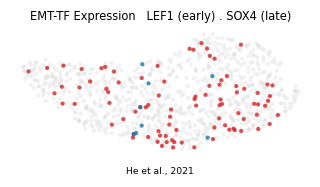

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'He et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean()
print(f'shown-cell pseudotime separation (late {late_tf} - early {early_tf}) = {sep:+.2f}')
print('saved expression.pdf')